# Introduction to numerical algorithms
## Practice class 9 — Gaussian random numbers, fitting and error propagation

In this practice you will generate normally distributed numbers with the Box–Müller method, fit models to data with the least-squares method, and check the error propagation formulas with simulated measurements.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Create the generator once, then keep using it.
rng = np.random.default_rng(2026)

### A few useful commands

| Command | Meaning |
| --- | --- |
| `rng.random(n)` | An array of `n` uniform random numbers in $[0,1)$ |
| `rng.normal(mu, sigma, n)` | `n` normal random numbers (use it for checking, **not** in Task 0) |
| `np.sum(x)`, `np.mean(x)`, `np.std(x, ddof=1)` | Sum, mean and sample standard deviation |
| `params, pcov = curve_fit(f, x, y, p0=[...])` | Least-squares fit of the model `f(x, *params)` |
| `np.sqrt(np.diag(pcov))` | Standard errors of the fitted parameters |
| `np.polyfit(x, y, deg)` | Polynomial least-squares fit, highest power first (for checking) |
| `ax.set_yscale("log")`, `ax.set_xscale("log")` | Logarithmic axes |

### Task 0 — Box–Müller method

Let $(x,y)$ be a pair of independent standard normal random numbers. Their joint density
$$f(x,y)=\frac{1}{2\pi}e^{-(x^2+y^2)/2}$$
is radially symmetric. In polar coordinates $x=r\cos\varphi$, $y=r\sin\varphi$:

* the angle $\varphi$ is uniform on $[0,2\pi)$;
* the radius has cumulative distribution $G(r)=1-e^{-r^2/2}$, which can be inverted (inverse CDF method from class 8).

**Algorithm** (one step gives **two** independent normal numbers):

1. Draw two independent uniform numbers $u_1,u_2\in[0,1)$.
2. $r=\sqrt{-2\ln(1-u_2)}$. We use $1-u_2\in(0,1]$ because `rng.random()` may return exactly $0$, and $\ln 0=-\infty$.
3. $\varphi=2\pi u_1$.
4. $z_0=r\cos\varphi$, $z_1=r\sin\varphi$.

Complete `box_muller(n, rng)`. Generate the `m` pairs **in one go with arrays** (no Python loop), put all $z_0$ values first and all $z_1$ values after them, and return exactly `n` numbers (if `n` is odd, drop the last one).

To get a general normal distribution $N(\mu,\sigma)$ use $\mu+\sigma z$.

In [7]:
def box_muller(n, rng):
    m = (n + 1)        # number of pairs needed
    # Work Here!
    u1 = rng.random(m)
    u2 = rng.random(m)
    r = np.sqrt(-2 * np.log(u1))
    theta = 2 * np.pi * u2
    z = r * np.sin(theta)
    return z[:n]

#### Check

For a standard normal distribution the mean is $0$, the variance is $1$, and
$P(|z|<1)\approx 0.6827$, $P(|z|<2)\approx 0.9545$. The right panel shows the pairs $(z_0,z_1)$: the cloud should be circularly symmetric, without any structure.

Mean:       0.0022   expected  0
Variance:   1.0042   expected  1
P(|z|<1):   0.6815   expected  0.6827
P(|z|<2):   0.9543   expected  0.9545


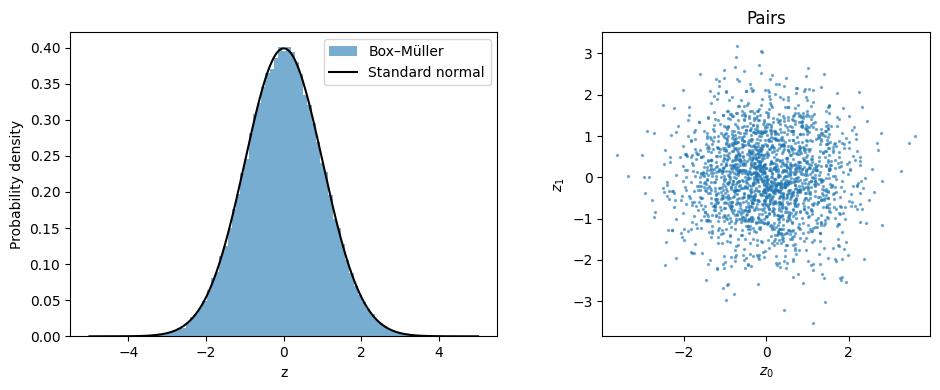

In [8]:
n = 100000
z = box_muller(n, rng)
assert z.shape == (n,)
assert box_muller(7, rng).shape == (7,)   # odd n must also work

print(f"Mean:      {z.mean(): .4f}   expected  0")
print(f"Variance:  {z.var(): .4f}   expected  1")
print(f"P(|z|<1):  {np.mean(np.abs(z) < 1): .4f}   expected  0.6827")
print(f"P(|z|<2):  {np.mean(np.abs(z) < 2): .4f}   expected  0.9545")

grid = np.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(z, bins=80, density=True, alpha=0.6, label="Box–Müller")
axes[0].plot(grid, np.exp(-grid**2 / 2) / np.sqrt(2 * np.pi), "k-", label="Standard normal")
axes[0].set(xlabel="z", ylabel="Probability density")
axes[0].legend()
axes[1].scatter(z[:2000], z[n // 2:n // 2 + 2000], s=2, alpha=0.5)
axes[1].set(xlabel=r"$z_0$", ylabel=r"$z_1$", aspect="equal", title="Pairs")
plt.tight_layout()
plt.show()

### Task 1 — Fitting

We have data points $(x_i,y_i)$, $i=1,\dots,n$, and a model $\hat y(x)$ with some parameters. The **least-squares** fit chooses the parameters that minimize the total squared error

$$E=\sum_{i=1}^n\bigl(\hat y(x_i)-y_i\bigr)^2 .$$

The differences $e_i=\hat y(x_i)-y_i$ are the **residuals**.

#### 1a. Straight line from the formula

For the model $\hat y(x)=ax+b$ the minimum of $E(a,b)$ is where $\partial E/\partial a=0$ and $\partial E/\partial b=0$. Solving these two linear equations gives

$$a=\frac{n\sum x_iy_i-\sum x_i\sum y_i}{n\sum x_i^2-\left(\sum x_i\right)^2},\qquad
b=\frac{\sum y_i-a\sum x_i}{n}=\bar y-a\bar x .$$

Complete `linear_fit(x, y)` using **only sums** (`np.sum`), no fitting library. You will reuse this function in 1c, 1d and 2c.

The data below are a line with $a=2$, $b=1$ plus Gaussian noise.

In [12]:
def linear_fit(x, y):
    # Least-squares line y = a*x + b. Return (a, b).
    # Work Here!
    a  = n*np.sum(x*y) - np.sum(x)*np.sum(y)
    a /= n*np.sum(x**2) - np.sum(x)**2
    b  = np.mean(y) - a*np.mean(x)
    return a, b

Formula:    a = 2.1569, b = 0.3472
np.polyfit: a = 1.9646, b = 1.3084
Total squared error E = 28.654


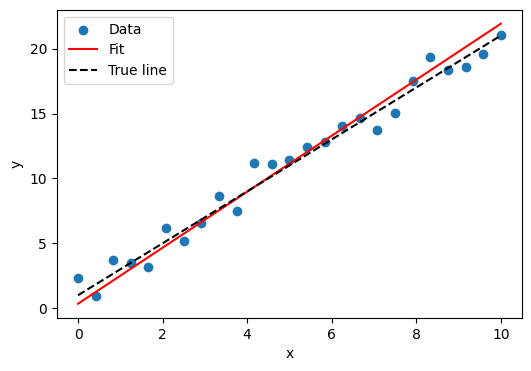

In [13]:
a_true, b_true = 2.0, 1.0
x_lin = np.linspace(0, 10, 25)
y_lin = a_true * x_lin + b_true + rng.normal(0, 1.0, x_lin.size)

a_fit, b_fit = linear_fit(x_lin, y_lin)
print(f"Formula:    a = {a_fit:.4f}, b = {b_fit:.4f}")
print("np.polyfit: a = {:.4f}, b = {:.4f}".format(*np.polyfit(x_lin, y_lin, 1)))
print(f"Total squared error E = {np.sum((a_fit * x_lin + b_fit - y_lin)**2):.3f}")

plt.figure(figsize=(6, 4))
plt.scatter(x_lin, y_lin, label="Data")
plt.plot(x_lin, a_fit * x_lin + b_fit, "r-", label="Fit")
plt.plot(x_lin, a_true * x_lin + b_true, "k--", label="True line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

**Optional.** Estimate the uncertainties of the parameters. With $S_{xx}=\sum(x_i-\bar x)^2$ and $s^2=E_{\min}/(n-2)$:

$$\sigma_a=\frac{s}{\sqrt{S_{xx}}},\qquad \sigma_b=s\sqrt{\frac1n+\frac{\bar x^2}{S_{xx}}}.$$

Compute them here; in 1b you can compare them with the values `curve_fit` gives.

In [ ]:
# Work Here! (optional)

#### 1b. Fitting with `scipy.optimize.curve_fit`

`curve_fit(model, x, y, p0=...)` minimizes the same $E$ for **any** model function `model(x, p1, p2, ...)`. For nonlinear models it works iteratively from the starting guess `p0`, so a bad `p0` can lead to a wrong (local) minimum. It returns the best parameters and their covariance matrix `pcov`; the standard errors are `np.sqrt(np.diag(pcov))`.

**(i) Line.** Write `model_line` and fit the data of 1a with `curve_fit`. Do you get the same $a,b$ as with your formula? (Optional: compare the errors too.)

In [14]:
def model_line(x, a, b):
    # Work Here!
    return a*x + b

# Work Here! Fit x_lin, y_lin and print the parameters with their errors.
a, b = curve_fit(model_line, x_lin, y_lin)[0]
print(f"a = {a}, b = {b}")

a = 1.9646495597224658, b = 1.3083584814581577


**(ii) Line or parabola?** The data below come from a parabola. Fit both a line and a parabola $\hat y=ax^2+bx+c$ with `curve_fit`.

Plot the data with both fits (left) and the **residuals** of both fits against $x$ (right). Print $E$ for both models.

* How do the residuals of a *good* model look? And of a wrong model?
* A model with more parameters always gives a smaller (or equal) $E$. Why is a small $E$ alone not a proof that the model is right?

a = 0.8178481445625434, b = -1.950550824673053, c = 0.6793616357243414
Total squared error E = 32.201


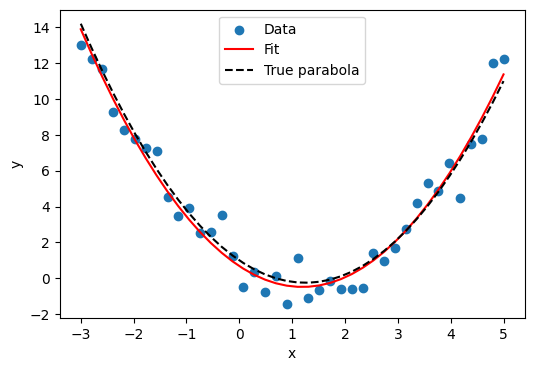

a = 1.9646495597224658, b = 1.3083584814581577


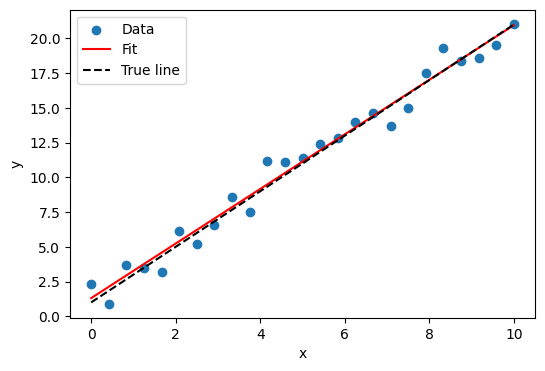

Total squared error E = 20.313


In [21]:
x_par = np.linspace(-3, 5, 40)
y_par = 0.8 * x_par**2 - 2.0 * x_par + 1.0 + rng.normal(0, 1.0, x_par.size)


def model_parabola(x, a, b, c):
    # Work Here!
    return a*x**2 + b*x + c


# Work Here! Fit both models, print E, make the two plots.
a, b, c = curve_fit(model_parabola, x_par, y_par)[0]
print(f"a = {a}, b = {b}, c = {c}")
print(f"Total squared error E = {np.sum((a * x_par**2 + b * x_par + c - y_par)**2):.3f}")
plt.figure(figsize=(6, 4))
plt.scatter(x_par, y_par, label="Data")
plt.plot(x_par, a * x_par**2 + b * x_par + c, "r-", label="Fit")
plt.plot(x_par, 0.8 * x_par**2 - 2.0 * x_par + 1.0, "k--", label="True parabola")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

a, b = curve_fit(model_line, x_lin, y_lin)[0]
print(f"a = {a}, b = {b}")

plt.figure(figsize=(6, 4))
plt.scatter(x_lin, y_lin, label="Data")
plt.plot(x_lin, a * x_lin + b, "r-", label="Fit")
plt.plot(x_lin, a_true * x_lin + b_true, "k--", label="True line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

print(f"Total squared error E = {np.sum((a * x_lin + b - y_lin)**2):.3f}")

**(iii) Nonlinear model, starting guess.** Fit $\hat y=a\sin(bx)$ to the data below. Try `p0=[2, 2]` and `p0=[1, 3]`. Plot both fits and print $E$. What went wrong in the second case, and how can you choose a good `p0`?

a = 0.35313954593346164, b = 2.70638766665209
Total squared error E = 174.770


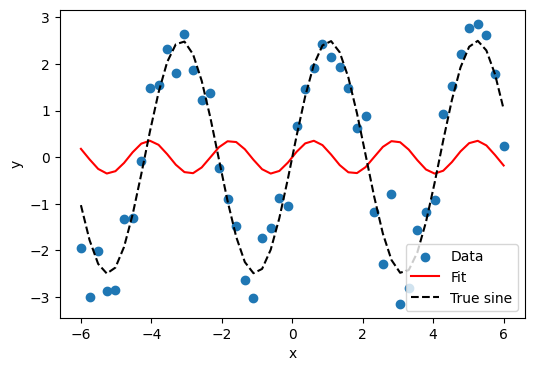

a = 0.3531525524112165, b = 2.706409518679692
Total squared error E = 174.770


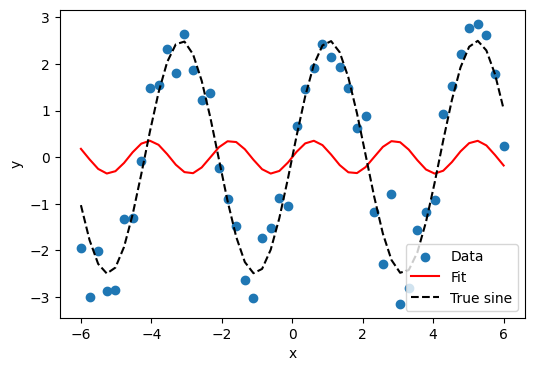

In [22]:
x_sin = np.linspace(-6, 6, 50)
y_sin = 2.5 * np.sin(1.5 * x_sin) + rng.normal(0, 0.5, x_sin.size)


def model_sin(x, a, b):
    return a * np.sin(b * x)

p0 = [2,2]

a, b = curve_fit(model_sin, x_sin, y_sin, p0=p0)[0]
print(f"a = {a}, b = {b}")
print(f"Total squared error E = {np.sum((a * np.sin(b * x_sin) - y_sin)**2):.3f}")

plt.figure(figsize=(6, 4))
plt.scatter(x_sin, y_sin, label="Data")
plt.plot(x_sin, a * np.sin(b * x_sin), "r-", label="Fit")
plt.plot(x_sin, 2.5 * np.sin(1.5 * x_sin), "k--", label="True sine")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

p0 = [1,3]
a, b = curve_fit(model_sin, x_sin, y_sin, p0=p0)[0]
print(f"a = {a}, b = {b}")
print(f"Total squared error E = {np.sum((a * np.sin(b * x_sin) - y_sin)**2):.3f}")

plt.figure(figsize=(6, 4))
plt.scatter(x_sin, y_sin, label="Data")
plt.plot(x_sin, a * np.sin(b * x_sin), "r-", label="Fit")
plt.plot(x_sin, 2.5 * np.sin(1.5 * x_sin), "k--", label="True sine")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()


#### 1c. Exponential: fit on linear or on logarithmic scale?

The data below follow $y=Ae^{-kx}$ with $A=2.5$, $k=1.5$ and **multiplicative** noise (each point has about 20% relative error), which is typical for decaying quantities.

Fit it in two ways:

1. **Direct fit** with `curve_fit` and the model $Ae^{-kx}$ (use `p0=[1, 1]`).
2. **Log fit:** take the logarithm, $\ln y=\ln A-kx$. This is a straight line in $x$, so use your `linear_fit(x, np.log(y))`. Then $k=-a$ and $A=e^{b}$.

Print $A$ and $k$ from both methods. Make **two panels** with the data and both fitted curves: on the left with a linear $y$ axis, on the right with a logarithmic $y$ axis (`ax.set_yscale("log")`).

* Which fit follows the data at large $x$? Which one at small $x$?
* In the direct fit, which points determine $E$? Why are the small values almost ignored?
* Why does the log fit suit relative (multiplicative) errors? When is it **not** usable (think of $y\le0$ or additive noise)?

A = 2.769208223585614, k = 1.7661157347691792
Total squared error E = 0.098


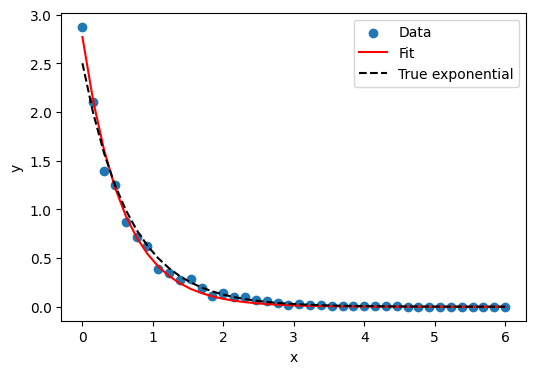

A = 1.2638174189445732, k = 1.2920424444753527
Total squared error E = 4.586


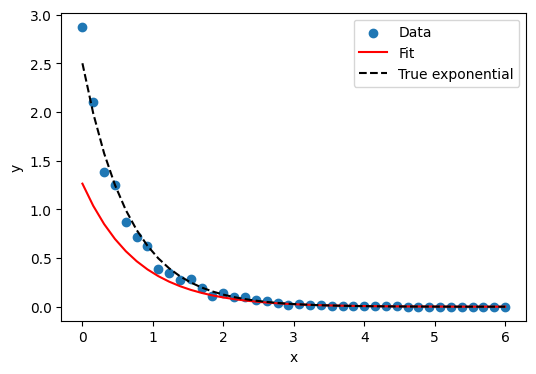

In [26]:
x_exp = np.linspace(0, 6, 40)
y_exp = 2.5 * np.exp(-1.5 * x_exp) * np.exp(rng.normal(0, 0.2, x_exp.size))


def model_exp(x, A, k):
    return A * np.exp(-k * x)


# Work Here!
p0 = [1,1]
A, k = curve_fit(model_exp, x_exp, y_exp, p0=p0)[0]
print(f"A = {A}, k = {k}")
print(f"Total squared error E = {np.sum((A * np.exp(-k * x_exp) - y_exp)**2):.3f}")

plt.figure(figsize=(6, 4))
plt.scatter(x_exp, y_exp, label="Data")
plt.plot(x_exp, A * np.exp(-k * x_exp), "r-", label="Fit")
plt.plot(x_exp, 2.5 * np.exp(-1.5 * x_exp), "k--", label="True exponential")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

A, k = linear_fit(x_exp, np.log(y_exp))
print(f"A = {np.exp(k)}, k = {-A}")
print(f"Total squared error E = {np.sum((np.exp(k) * np.exp(-(-A) * x_exp) - y_exp)**2):.3f}")
plt.figure(figsize=(6, 4))
plt.scatter(x_exp, y_exp, label="Data")
plt.plot(x_exp, np.exp(k) * np.exp(-(-A) * x_exp), "r-", label="Fit")
plt.plot(x_exp, 2.5 * np.exp(-1.5 * x_exp), "k--", label="True exponential")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

#### 1d. Power law: straight line on a log-log plot

A power law $y=Cx^{\alpha}$ becomes a straight line after taking the logarithm of **both** variables:

$$\ln y=\ln C+\alpha\ln x .$$

The slope on a log-log plot is the exponent $\alpha$. The data below have $C=3$, $\alpha=-1.7$, multiplicative noise, and $x$ values equally spaced on a logarithmic scale.

1. Plot the data with linear axes and with log-log axes, next to each other. Which plot tells you more?
2. Fit with `linear_fit(np.log(x), np.log(y))`: $\alpha=a$, $C=e^{b}$.
3. Fit directly with `curve_fit` and the model $Cx^{\alpha}$.
4. Show both fits on the log-log plot and compare the parameters with the true values.

C = 5.140560825531049, alpha = -1.4510283130616333
Total squared error E = 935.691


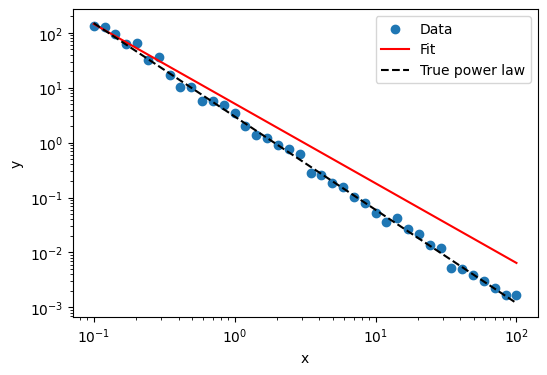

In [27]:
x_pow = np.logspace(-1, 2, 40)
y_pow = 3.0 * x_pow**(-1.7) * np.exp(rng.normal(0, 0.2, x_pow.size))


def model_power(x, C, alpha):
    return C * x**alpha


# Work Here!
plt.figure(figsize=(6, 4))
plt.scatter(x_pow, y_pow, label="Data")
p0 = [1, -1]
C, alpha = curve_fit(model_power, x_pow, y_pow, p0=p0)[0]
print(f"C = {C}, alpha = {alpha}")
print(f"Total squared error E = {np.sum((C * x_pow**alpha - y_pow)**2):.3f}")
plt.plot(x_pow, C * x_pow**alpha, "r-", label="Fit")
plt.plot(x_pow, 3.0 * x_pow**(-1.7), "k--", label="True power law")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

#### 1e. Exponential or power law? (optional)

Both data sets below decay. Plot each of them on a semi-log plot (log $y$) **and** on a log-log plot. An exponential is a straight line on the semi-log plot; a power law is a straight line on the log-log plot. Decide which is which, then fit the appropriate straight line and give the parameters.

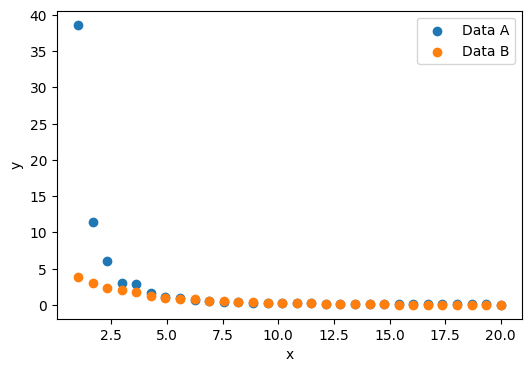

Data A: a = 0.12206224227983478, b = -3.167755659535526, c = 18.219158684039126
Total squared error E = 800.431


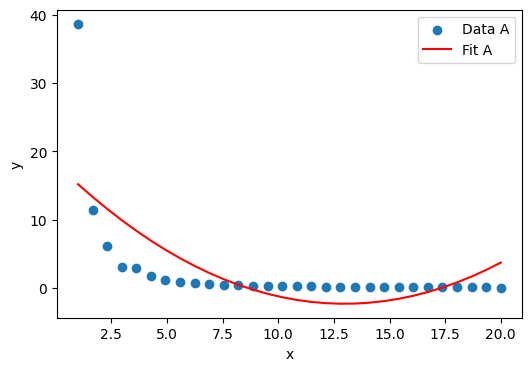

Data B: a = -0.13844465528615713, b = 2.1334232419554207
Total squared error E = 9.473


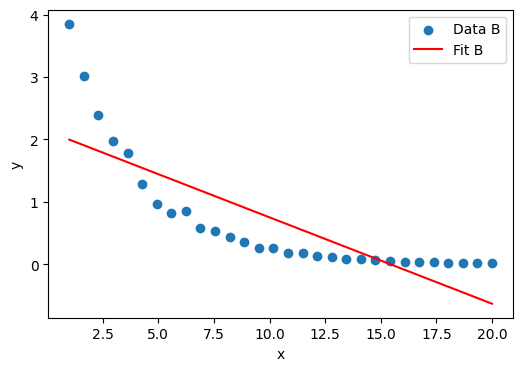

In [29]:
x_m = np.linspace(1, 20, 30)
y_A = 40 * x_m**(-2.2) * np.exp(rng.normal(0, 0.1, x_m.size))
y_B = 5 * np.exp(-0.3 * x_m) * np.exp(rng.normal(0, 0.1, x_m.size))

# Work Here!
plt.figure(figsize=(6, 4))
plt.scatter(x_m, y_A, label="Data A")
plt.scatter(x_m, y_B, label="Data B")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

a, b, c = curve_fit(model_parabola, x_m, y_A)[0]
print(f"Data A: a = {a}, b = {b}, c = {c}")
print(f"Total squared error E = {np.sum((a * x_m**2 + b * x_m + c - y_A)**2):.3f}")
plt.figure(figsize=(6, 4))
plt.scatter(x_m, y_A, label="Data A")
plt.plot(x_m, a * x_m**2 + b * x_m + c, "r-", label="Fit A")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

a, b = curve_fit(model_line, x_m, y_B)[0]
print(f"Data B: a = {a}, b = {b}")
print(f"Total squared error E = {np.sum((a * x_m + b - y_B)**2):.3f}")
plt.figure(figsize=(6, 4))
plt.scatter(x_m, y_B, label="Data B")
plt.plot(x_m, a * x_m + b, "r-", label="Fit B")
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

### Task 2 — Error propagation

Sources of errors in data:
 * Precision of the instrument
 * Human error
 * Stochastic nature of the data/phenomena
 * Environment
 * etc.

Error types:
 * **Random**
   * Always repeat the experiment if possible, to reduce the random error (see below).
 * **Systematic**
   * Repeat the measurement in different environments, which may cancel out the systematic error. Vary parameters which may show the direction and magnitude of the error.
   * Repetition does not reduce a systematic error.

#### Random errors

Random errors are supposed to have a normal distribution with mean $\mu$ and standard deviation $\sigma$. If the data read $x_1,x_2,\dots,x_n$, these quantities are estimated as
$$
\bar x = \frac{1}{n}\sum_{i=1}^n x_i,\qquad
\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^n(x_i-\bar x)^2}.
$$
For the sample standard deviation it is customary to use $n-1$ in the denominator, which corrects the bias caused by using $\bar x$ instead of the true mean:
$$
s_x = \sqrt{\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar x)^2}.
$$

**Some customary definitions**

 * Often we are interested in the **standard deviation of the mean**:
$$
\sigma_{\bar x}=\frac{s_x}{\sqrt n}=\sqrt{\frac{1}{n(n-1)}\sum_{i=1}^n(x_i-\bar x)^2}.
$$
This also shows that if we measure $n$ data points, the standard deviation of the mean is reduced by a factor $\sqrt{n}$.
 * **68% confidence interval**: $\bar x \pm \sigma_{\bar x}$
 * **95% confidence interval**: $\bar x \pm 2\sigma_{\bar x}$
 * **99.7% confidence interval**: $\bar x \pm 3\sigma_{\bar x}$
 * A confidence interval of the mean measures the uncertainty in the estimate of the mean and is generally written as $\bar x \pm \Delta x$.

The question we answer here is what happens to the errors if we combine measured quantities with arithmetic operations.

#### Two-variable operations

Any differentiable function $f(a,b)$ of two variables can be expanded around the mean values $\mu_a,\mu_b$ to first order:
$$f(a,b)\approx f(\mu_a,\mu_b)+\frac{\partial f}{\partial a}(a-\mu_a)+\frac{\partial f}{\partial b}(b-\mu_b).$$
Taking the variance of both sides and using the formula for the variance of a linear combination,
$$\operatorname{Var}(pX + qY) = p^2\operatorname{Var}(X) + q^2\operatorname{Var}(Y) + 2pq \operatorname{Cov}(X, Y),$$
we obtain
$$\sigma^2_f\approx\left( \frac{\partial f}{\partial a}\right) ^2\sigma^2_a+\left( \frac{\partial f}{\partial b}\right)^2\sigma^2_b+2\frac{\partial f}{\partial a}\frac{\partial f} {\partial b}\sigma_{ab},$$
where the derivatives are taken at $(\mu_a,\mu_b)$, and $\sigma_{ab} = \sigma_{a}\sigma_{b} \rho_{ab}$ is the covariance of $a$ and $b$. If $a$ and $b$ are uncorrelated, $\sigma_{ab}= 0$. The predicted mean is $\mu_f\approx f(\mu_a,\mu_b)$.

#### Special cases (independent variables)
 * **Multiplication by a constant**: $f=Ca$: $\quad\sigma_f=|C|\sigma_a$
 * **Addition/subtraction:** $f=a\pm b$: all derivatives are $\pm1$, so $\sigma_f=\sqrt{\sigma_a^2+\sigma_b^2}$. Together with the previous rule, this gives the $1/\sqrt{n}$ factor for the mean of $n$ independent measurements.
 * **Product/division:** $f=ab$ or $f=a/b$: the *relative* errors add in quadrature:
 $$\frac{\sigma_f}{|f|}=\sqrt{\left(\frac{\sigma_a}{a}\right)^2+\left(\frac{\sigma_b}{b}\right)^2}$$
 * **Power:** $f=a^\gamma$: $\quad\sigma_f = \left|\gamma f\, \dfrac{\sigma_a}{a}\right|$

These are first-order (linear) approximations. They work well when the relative errors are small.

#### 2a. Check the rules with simulated measurements

We simulate $100\,000$ repeated measurements of two independent quantities, $a\sim N(10, 0.5)$ and $b\sim N(4, 0.3)$. (You may use your own `box_muller` instead of `rng.normal`: `mu + sigma * box_muller(n, rng)`.)

In a real experiment we do not know the true $\mu$ and $\sigma$; we estimate them from the data. `norm.fit(values)` fits a normal distribution and returns the estimated mean and standard deviation. The two cells below are given: they generate the data, fit $a$ and $b$, and plot the histograms (stars) with the fitted densities (lines).

In [30]:
from scipy.stats import norm

n_meas = 100000
a = rng.normal(10.0, 0.5, n_meas)
b = rng.normal(4.0, 0.3, n_meas)


def hist(x, bins=50):
    # Normalized histogram: returns the densities and the bin centers.
    edges = np.linspace(x.min(), x.max(), bins + 1)
    h, _ = np.histogram(x, bins=edges, density=True)
    return h, (edges[1:] + edges[:-1]) / 2

a: mu = 9.9998, sigma = 0.4981
b: mu = 3.9999, sigma = 0.3001


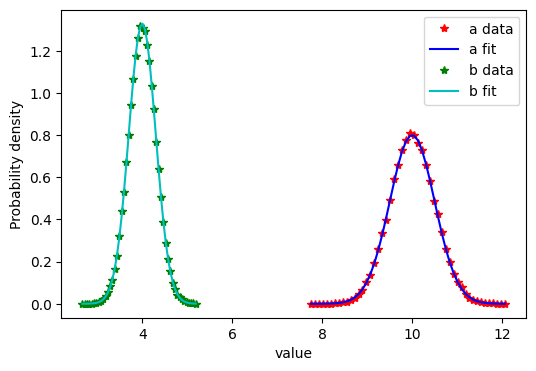

In [31]:
mua, sa = norm.fit(a)
mub, sb = norm.fit(b)
print(f"a: mu = {mua:.4f}, sigma = {sa:.4f}")
print(f"b: mu = {mub:.4f}, sigma = {sb:.4f}")

plt.figure(figsize=(6, 4))
h, x = hist(a)
plt.plot(x, h, "r*", label="a data")
plt.plot(x, norm.pdf(x, mua, sa), "b-", label="a fit")
h, x = hist(b)
plt.plot(x, h, "g*", label="b data")
plt.plot(x, norm.pdf(x, mub, sb), "c-", label="b fit")
plt.xlabel("value"); plt.ylabel("Probability density"); plt.legend()
plt.show()

**Your task.** Calculate new quantities from the measurements: $Ca$, $a+b$, $a-b$, $ab$, $a/b$ and $a^\gamma$ (with $C=3$, $\gamma=1/2$).

For each of them, use the formulas above and the **fitted** values `mua, sa, mub, sb` to **calculate** the predicted mean and standard deviation, and write them into `predictions`.

The helper `check` then fits a normal distribution to the simulated values with `norm.fit`, prints the *measured* and the *calculated* values, and plots the histogram (stars) together with the normal density from your prediction (line). The two should agree.

In [32]:
C, gamma = 3.0, 0.5


def check(values, prediction, label, ax):
    mu_m, s_m = norm.fit(values)
    h, x = hist(values)
    ax.plot(x, h, "r*")
    ax.set_title(label)
    if prediction is None or None in prediction:
        print(f"{label:>9}  Measured: {mu_m:9.4f} {s_m:.4f}   Calculated: (not yet)")
        return
    mu_p, s_p = prediction
    ax.plot(x, norm.pdf(x, mu_p, s_p), "b-")
    print(f"{label:>9}  Measured: {mu_m:9.4f} {s_m:.4f}   Calculated: {mu_p:9.4f} {s_p:.4f}")

In [34]:
# Work Here! Replace each (None, None) by (calculated mean, calculated sigma),
# using mua, sa, mub, sb, C and gamma.
predictions = {
    "C*a":      (C * mua, C * sa),
    "a+b":      (mua + mub, np.sqrt(sa**2 + sb**2)),
    "a-b":      (mua - mub, np.sqrt(sa**2 + sb**2)),
    "a*b":      (mua * mub, np.sqrt((sa/mua)**2 + (sb/mub)**2) * (mua * mub)),
    "a/b":      (mua / mub, np.sqrt((sa/mua)**2 + (sb/mub)**2) * (mua / mub)),
    "a**gamma": (mua ** gamma, gamma * (mua ** (gamma - 1)) * sa),
}

      C*a  Measured:   29.9993 1.4944   Calculated:   29.9993 1.4944
      a+b  Measured:   13.9996 0.5805   Calculated:   13.9996 0.5815
      a-b  Measured:    5.9999 0.5826   Calculated:    5.9999 0.5815
      a*b  Measured:   39.9970 3.5979   Calculated:   39.9976 3.6017
      a/b  Measured:    2.5144 0.2299   Calculated:    2.5000 0.2251
 a**gamma  Measured:    3.1613 0.0788   Calculated:    3.1622 0.0788


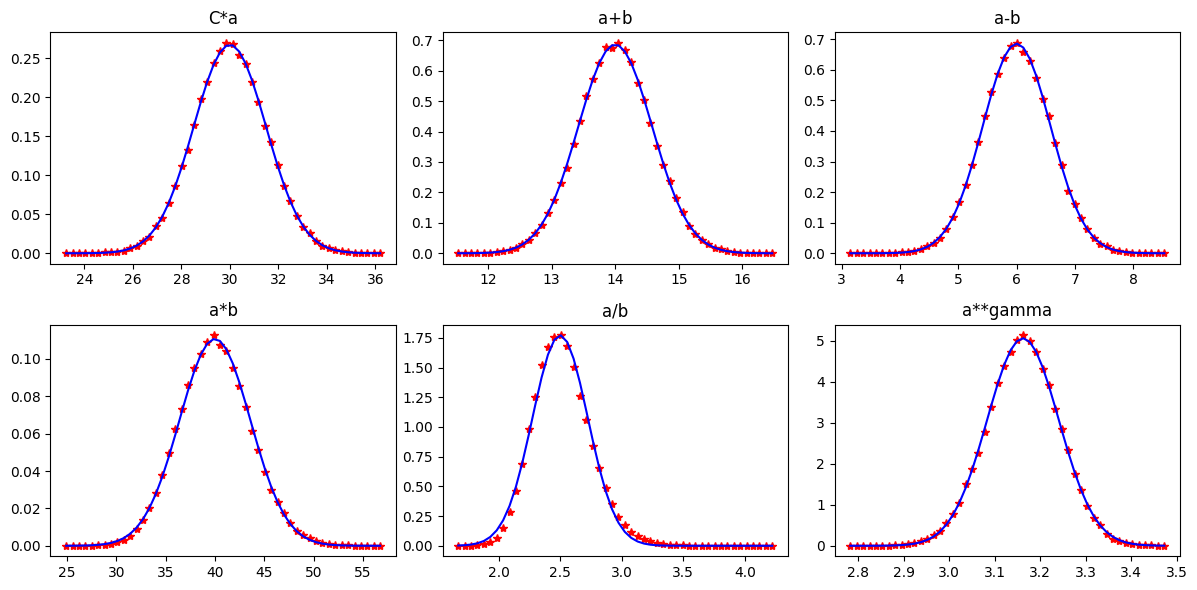

In [35]:
results = {
    "C*a": C * a, "a+b": a + b, "a-b": a - b,
    "a*b": a * b, "a/b": a / b, "a**gamma": a**gamma,
}
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (label, values) in zip(axes.flat, results.items()):
    check(values, predictions[label], label, ax)
plt.tight_layout()
plt.show()